In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## correlation

**Figure 2: Reward model score versus human rating for 300 responses.** Each dot is one response, with its human rating averaged over annotators on a 1–7 Likert scale; the line is a least-squares fit. The reward model's scores correlate strongly with human ratings (Pearson r = 0.86, n = 300).

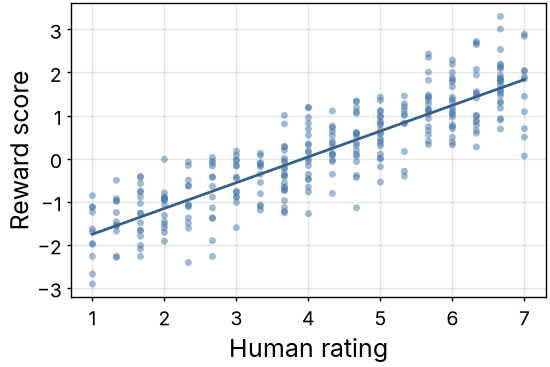

In [2]:
with open("../data/correlation.json") as f:
    data = json.load(f)
human = np.array(data["human_rating"])
reward = np.array(data["reward_score"])

fig, ax = plt.subplots(figsize=(2.75, 2), layout="constrained")

ax.scatter(human, reward, s=6.25, color=colors["series-1"], edgecolors="none", alpha=0.5)
slope, intercept = np.polyfit(human, reward, 1)
ax.plot([1, 7], [slope * 1 + intercept, slope * 7 + intercept], color=darken(colors["series-1"]))

ax.set_xticks(range(1, 8))
ax.set_xlabel("Human rating")
ax.set_ylabel("Reward score")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/correlation.pdf")
fig.savefig("../outputs/correlation.png")
plt.show()